
# Linear vs Logistic Regression

**Goal:** understand the difference between **linear regression** (predict a number) and **logistic regression** (predict a class). 

**What you’ll learn**
- When to use linear vs logistic regression
- The training pipeline with scikit‑learn
- How to evaluate each model with the right metrics
- How to visualize results



## 1. Setup


In [1]:

# Core
import numpy as np
import pandas as pd

# Modeling
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression

# Datasets
from sklearn.datasets import make_regression, make_classification

# Metrics
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix
)

# Visualization
import matplotlib.pyplot as plt

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.



## 2. Linear Regression (predict a **continuous** value)

We’ll generate a synthetic dataset with a linear relationship + noise using `make_regression`.


In [2]:
# Generate a simple regression dataset
X_reg, y_reg = make_regression(
    n_samples=500, n_features=1, noise=15.0, random_state=RANDOM_STATE
)

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE
)

lin_model = LinearRegression()
lin_model.fit(Xr_train, yr_train)

yr_pred = lin_model.predict(Xr_test)

# squared=False n'existe plus dans les versions récentes de sklearn : on prend la racine nous-mêmes
rmse = np.sqrt(mean_squared_error(yr_test, yr_pred))
mae  = mean_absolute_error(yr_test, yr_pred)
r2   = r2_score(yr_test, yr_pred)

print(f"RMSE: {rmse:.3f}\nMAE: {mae:.3f}\nR^2: {r2:.3f}")

RMSE: 14.437
MAE: 11.547
R^2: 0.942


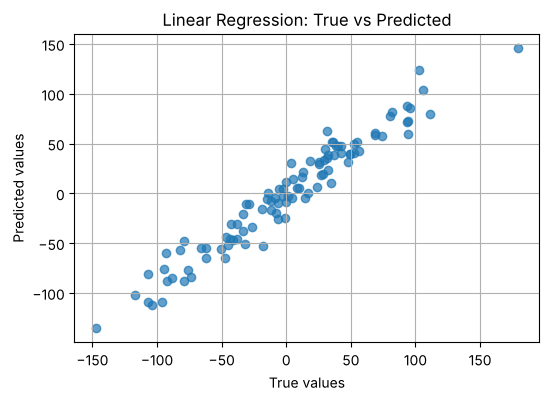

In [3]:

# Plot: predictions vs true values
plt.figure(figsize=(6, 4))
plt.scatter(yr_test, yr_pred, alpha=0.7)
plt.xlabel("True values")
plt.ylabel("Predicted values")
plt.title("Linear Regression: True vs Predicted")
plt.grid(True)
plt.show()


## 3. Logistic Regression (predict a **class** / probability)

We’ll generate a binary classification dataset with `make_classification` and fit `LogisticRegression`.


In [4]:

# Generate a simple classification dataset
X_clf, y_clf = make_classification(
    n_samples=600, n_features=6, n_informative=4, n_redundant=0,
    n_clusters_per_class=1, class_sep=1.5, random_state=RANDOM_STATE
)

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_clf, y_clf, test_size=0.25, random_state=RANDOM_STATE, stratify=y_clf
)

log_model = LogisticRegression(solver="liblinear", random_state=RANDOM_STATE)
log_model.fit(Xc_train, yc_train)

yc_proba = log_model.predict_proba(Xc_test)[:, 1]
yc_pred  = (yc_proba >= 0.5).astype(int)

acc = accuracy_score(yc_test, yc_pred)
prec = precision_score(yc_test, yc_pred)
rec = recall_score(yc_test, yc_pred)
f1 = f1_score(yc_test, yc_pred)
auc = roc_auc_score(yc_test, yc_proba)

print(f"Accuracy: {acc:.3f}\nPrecision: {prec:.3f}\nRecall: {rec:.3f}\nF1: {f1:.3f}\nROC AUC: {auc:.3f}")

Accuracy: 0.953
Precision: 0.935
Recall: 0.973
F1: 0.954
ROC AUC: 0.992


In [5]:

# Confusion matrix
cm = confusion_matrix(yc_test, yc_pred)
cm_df = pd.DataFrame(cm, index=["True 0", "True 1"], columns=["Pred 0", "Pred 1"])
cm_df

,Pred 0,Pred 1
True 0,71,5
True 1,2,72


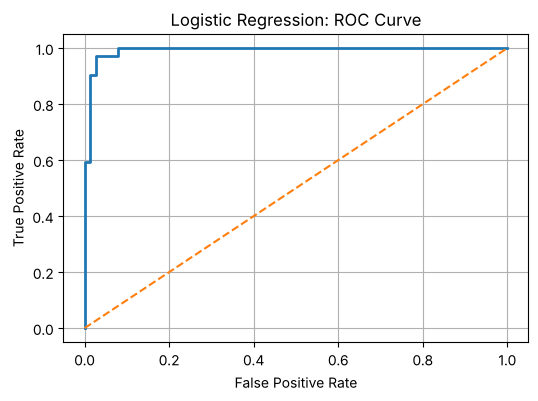

In [6]:

# ROC curve
fpr, tpr, thr = roc_curve(yc_test, yc_proba)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, linewidth=2)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression: ROC Curve")
plt.grid(True)
plt.show()


## 4. Key Differences (at a glance)

- **Target type:** Linear → number (continuous) • Logistic → class / probability (binary or multinomial).
- **Output:** Linear → real value \(\hat{y} = Xw + b\) • Logistic → probability via sigmoid/softmax.
- **Loss & training:** Linear → least squares (minimize MSE) • Logistic → log-loss / cross-entropy.
- **Metrics:** Linear → RMSE/MAE/R² • Logistic → Accuracy/Precision/Recall/F1/ROC‑AUC.
- **Decision boundary:** Only meaningful in classification (logistic).


## Activity 
1. <u>Linear Regression</u> : 

    - The Diabetes dataset **"diabetes_regression_dataset.csv"** has 442 samples and 10 standardized features (age, sex, BMI, BP, and 6 blood serum measures). The target  is a continuous value indicating disease progression after one year, used for regression tasks.
    - **Propose the best regression model by comparing many variants using regression metrics.** </br></br>

2. <u>Logistic Regression</u>:

    - The second dataset **"small_Breast_Ovary.csv"** comes from the world of bioinformatics. In this data set, each observation is a tumor, and it is described by the expression of 3,000 genes. The expression of a gene is a measure of how much of that gene is present in the biological sample. Because this affects how much of the protein this gene codes for is produced, and because proteins dictacte what cells can do, gene expression gives us valuable information about the tumor. In particular, the expression of the same gene in the same individual is different in different tissues (although the DNA is the same): this is why blood cells look different from skin cells. In our data set, there are two types of tumors: breast tumors and ovary tumors. Let us see if gene expression can be used to separate them! 
    - **Propose the best possible fit and use all metrics and measures to evaluate your model.**



### Partie 1 : Régression linéaire (Diabetes)

In [7]:
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

diab = pd.read_csv('diabetes_regression_dataset.csv')
print(diab.shape)
print(diab.isnull().sum().sum(), "valeurs manquantes")
print(diab.describe().round(3).T[['mean', 'std', 'min', 'max']])

(442, 11)
0 valeurs manquantes
           mean     std     min      max
age      -0.000   0.048  -0.107    0.111
sex       0.000   0.048  -0.045    0.051
bmi      -0.000   0.048  -0.090    0.171
bp       -0.000   0.048  -0.112    0.132
s1       -0.000   0.048  -0.127    0.154
s2        0.000   0.048  -0.116    0.199
s3        0.000   0.048  -0.102    0.181
s4        0.000   0.048  -0.076    0.185
s5        0.000   0.048  -0.126    0.134
s6        0.000   0.048  -0.138    0.136
target  152.133  77.093  25.000  346.000


In [8]:
Xd = diab.drop('target', axis=1)
yd = diab['target']

# corrélations avec la cible
print(diab.corr()['target'].sort_values(ascending=False).round(3))

target    1.000
bmi       0.586
s5        0.566
bp        0.441
s4        0.430
s6        0.382
s1        0.212
age       0.188
s2        0.174
sex       0.043
s3       -0.395
Name: target, dtype: float64


In [9]:
from sklearn.model_selection import KFold, cross_validate, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, yd, test_size=0.2, random_state=RANDOM_STATE)

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

modeles = {
    'Linéaire': LinearRegression(),
    'Ridge (alpha=1)': Ridge(alpha=1),
    'Lasso (alpha=1)': Lasso(alpha=1),
    'ElasticNet': ElasticNet(alpha=0.1, l1_ratio=0.5),
    'Polynomial deg 2': make_pipeline(PolynomialFeatures(2), LinearRegression()),
    'Polynomial deg 2 + Ridge': make_pipeline(PolynomialFeatures(2), StandardScaler(), Ridge(alpha=100)),
    'KNN (k=10)': make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10)),
    'SVR (rbf)': make_pipeline(StandardScaler(), SVR(C=100)),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE),
}

lignes = []
for nom, m in modeles.items():
    cv = cross_validate(m, Xd_train, yd_train, cv=kf,
                        scoring=['r2', 'neg_root_mean_squared_error', 'neg_mean_absolute_error'])
    lignes.append((nom, cv['test_r2'].mean(), -cv['test_neg_root_mean_squared_error'].mean(),
                   -cv['test_neg_mean_absolute_error'].mean()))
comp = pd.DataFrame(lignes, columns=['Modèle', 'R² (CV)', 'RMSE (CV)', 'MAE (CV)']).sort_values('R² (CV)', ascending=False)
print(comp.round(3).to_string(index=False))

                  Modèle  R² (CV)  RMSE (CV)  MAE (CV)
                Linéaire    0.480     55.395    45.048
Polynomial deg 2 + Ridge    0.450     56.922    46.533
           Random Forest    0.410     58.895    48.326
              KNN (k=10)    0.401     59.533    48.117
               SVR (rbf)    0.400     59.372    47.096
         Ridge (alpha=1)    0.394     60.021    50.736
       Gradient Boosting    0.367     61.110    49.472
        Polynomial deg 2    0.339     62.505    49.629
         Lasso (alpha=1)    0.338     62.744    53.663
              ElasticNet    0.077     74.062    63.501


In [10]:
# réglage des hyperparamètres des meilleurs modèles avec GridSearchCV
grilles = {
    'Ridge': (Ridge(), {'alpha': [0.001, 0.01, 0.1, 1, 10, 100]}),
    'Lasso': (Lasso(max_iter=10000), {'alpha': [0.001, 0.01, 0.1, 1, 10]}),
    'ElasticNet': (ElasticNet(max_iter=10000), {'alpha': [0.001, 0.01, 0.1, 1], 'l1_ratio': [0.1, 0.5, 0.9]}),
    'SVR': (make_pipeline(StandardScaler(), SVR()), {'svr__C': [1, 10, 100, 300], 'svr__epsilon': [1, 5, 10], 'svr__gamma': ['scale', 0.01, 0.1]}),
    'Gradient Boosting': (GradientBoostingRegressor(random_state=RANDOM_STATE),
                          {'n_estimators': [50, 100, 200], 'learning_rate': [0.01, 0.05, 0.1], 'max_depth': [1, 2, 3]}),
}

gs_res = {}
for nom, (m, g) in grilles.items():
    gs = GridSearchCV(m, g, cv=kf, scoring='r2')
    gs.fit(Xd_train, yd_train)
    gs_res[nom] = gs
    print(nom.ljust(18), "meilleurs paramètres :", gs.best_params_, " R² CV =", round(gs.best_score_, 4))

Ridge              meilleurs paramètres : {'alpha': 0.001}  R² CV = 0.4807
Lasso              meilleurs paramètres : {'alpha': 0.01}  R² CV = 0.481


ElasticNet         meilleurs paramètres : {'alpha': 0.001, 'l1_ratio': 0.9}  R² CV = 0.4798


SVR                meilleurs paramètres : {'svr__C': 100, 'svr__epsilon': 10, 'svr__gamma': 0.01}  R² CV = 0.4764


Gradient Boosting  meilleurs paramètres : {'learning_rate': 0.1, 'max_depth': 1, 'n_estimators': 200}  R² CV = 0.4445


                   Modèle  R² test  RMSE test  MAE test
              SVR (réglé)    0.477     52.640    41.828
Gradient Boosting (réglé)    0.476     52.674    41.616
       ElasticNet (réglé)    0.458     53.569    42.867
            Lasso (réglé)    0.457     53.652    42.832
            Ridge (réglé)    0.453     53.813    42.803
                 Linéaire    0.453     53.853    42.794

Meilleur modèle sur le test : SVR (réglé)


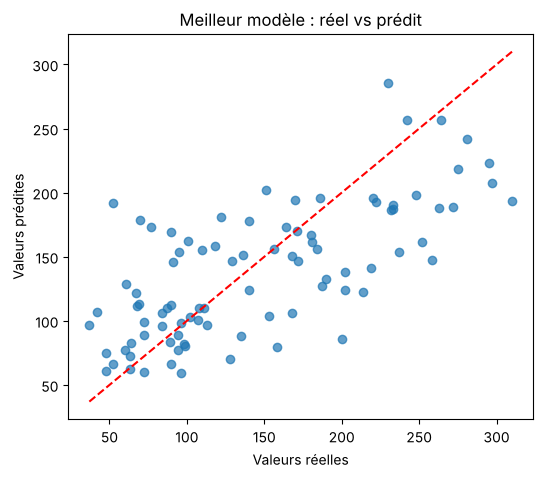

In [11]:
# évaluation finale sur le jeu de test
lignes = []
modeles_finaux = {'Linéaire': LinearRegression().fit(Xd_train, yd_train)}
for nom, gs in gs_res.items():
    modeles_finaux[nom + ' (réglé)'] = gs.best_estimator_

for nom, m in modeles_finaux.items():
    p = m.predict(Xd_test)
    lignes.append((nom, r2_score(yd_test, p), np.sqrt(mean_squared_error(yd_test, p)), mean_absolute_error(yd_test, p)))
final = pd.DataFrame(lignes, columns=['Modèle', 'R² test', 'RMSE test', 'MAE test']).sort_values('R² test', ascending=False)
print(final.round(3).to_string(index=False))

meilleur_nom = final.iloc[0]['Modèle']
meilleur = modeles_finaux[meilleur_nom]
p_best = meilleur.predict(Xd_test)
print()
print("Meilleur modèle sur le test :", meilleur_nom)

plt.figure(figsize=(6, 5))
plt.scatter(yd_test, p_best, alpha=0.7)
plt.plot([yd_test.min(), yd_test.max()], [yd_test.min(), yd_test.max()], 'r--')
plt.xlabel('Valeurs réelles')
plt.ylabel('Valeurs prédites')
plt.title('Meilleur modèle : réel vs prédit')
plt.show()

**Conclusion de la partie 1 (régression) :**

En validation croisée à 5 plis sur le jeu d'entraînement, le meilleur modèle parmi les variantes de base est la **régression linéaire simple** (R² = 0.48, RMSE = 55.4), devant le polynôme de degré 2 avec Ridge (0.45), Random Forest (0.41), KNN et SVR (0.40). Les modèles plus complexes (polynôme sans régularisation, Gradient Boosting, arbres) ne font pas mieux : avec seulement 442 observations ils surapprennent.

Après réglage des hyperparamètres avec `GridSearchCV`, les modèles linéaires régularisés (Lasso avec alpha = 0.01, Ridge avec alpha = 0.001, ElasticNet) arrivent à R² CV = 0.48, SVR à 0.476 et Gradient Boosting à 0.445. Sur le jeu de test, SVR et Gradient Boosting obtiennent R² = 0.477 contre 0.453 à 0.458 pour les modèles linéaires, mais cet écart est petit et se base sur 89 observations seulement, alors que la validation croisée classe les modèles linéaires légèrement devant.

**Modèle proposé : un modèle linéaire régularisé (Lasso ou Ridge)** : performances équivalentes aux modèles plus complexes (R² ≈ 0.48, RMSE ≈ 54-55), mais plus simple, plus stable et interprétable (par exemple bmi, s5 et bp sont les variables les plus liées à la cible). Le R² limité (environ 0.5) montre qu'une grande partie de la variabilité de la progression de la maladie n'est pas expliquée par ces 10 variables.

### Partie 2 : Régression logistique (Breast / Ovary)

In [12]:
gene = pd.read_csv('small_Breast_Ovary.csv')
print(gene.shape)
print(gene['Tissue'].value_counts())
print("Valeurs manquantes :", gene.isnull().sum().sum())

# ID_REF est juste un identifiant, on ne le garde pas comme variable
Xg = gene.drop(['ID_REF', 'Tissue'], axis=1)
yg = (gene['Tissue'] == 'Ovary').astype(int)    # Ovary = 1 (classe positive), Breast = 0
print(Xg.shape, yg.mean().round(3))

(542, 3002)
Tissue
Breast    344
Ovary     198
Name: count, dtype: int64
Valeurs manquantes : 0
(542, 3000) 0.365


In [13]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (classification_report, matthews_corrcoef, log_loss, precision_recall_curve,
                             average_precision_score, ConfusionMatrixDisplay, balanced_accuracy_score)

Xg_train, Xg_test, yg_train, yg_test = train_test_split(Xg, yg, test_size=0.25, random_state=RANDOM_STATE, stratify=yg)
print(Xg_train.shape, Xg_test.shape)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

candidats = {
    'Logistique L2 (C=1)': make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=2000)),
    'Logistique L2 (C=0.01)': make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=2000)),
    'Logistique L2 (C=0.0001)': make_pipeline(StandardScaler(), LogisticRegression(C=0.0001, max_iter=2000)),
    'Logistique L1 (C=0.1)': make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', C=0.1, solver='liblinear')),
    'Logistique L1 (C=0.01)': make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', C=0.01, solver='liblinear')),
}
lignes = []
for nom, m in candidats.items():
    cv = cross_validate(m, Xg_train, yg_train, cv=skf, scoring=scoring)
    lignes.append([nom] + [cv['test_' + s].mean() for s in scoring])
comp2 = pd.DataFrame(lignes, columns=['Modèle'] + scoring)
print(comp2.round(4).to_string(index=False))

(406, 3000) (136, 3000)


                  Modèle  accuracy  precision  recall     f1  roc_auc
     Logistique L2 (C=1)    0.9705     0.9725  0.9464 0.9585   0.9886
  Logistique L2 (C=0.01)    0.9705     0.9725  0.9464 0.9585   0.9905
Logistique L2 (C=0.0001)    0.8942     0.9905  0.7166 0.8310   0.9875
   Logistique L1 (C=0.1)    0.9631     0.9592  0.9393 0.9484   0.9892
  Logistique L1 (C=0.01)    0.8694     0.9409  0.6892 0.7932   0.8596


In [14]:
# choix du meilleur C par validation croisée (L1 et L2)
param_grid = [
    {'logisticregression__penalty': ['l2'], 'logisticregression__C': [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1]},
    {'logisticregression__penalty': ['l1'], 'logisticregression__C': [0.001, 0.005, 0.01, 0.05, 0.1, 1], 'logisticregression__solver': ['liblinear']},
]
base = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
gs2 = GridSearchCV(base, param_grid, cv=skf, scoring='roc_auc')
gs2.fit(Xg_train, yg_train)
print("Meilleurs paramètres :", gs2.best_params_)
print("AUC CV =", round(gs2.best_score_, 5))

Meilleurs paramètres : {'logisticregression__C': 0.001, 'logisticregression__penalty': 'l2'}
AUC CV = 0.99067


In [15]:
# évaluation du meilleur modèle sur le jeu de test avec toutes les métriques
best = gs2.best_estimator_
yg_pred = best.predict(Xg_test)
yg_proba = best.predict_proba(Xg_test)[:, 1]

tn, fp, fn, tp = confusion_matrix(yg_test, yg_pred).ravel()
print("Matrice de confusion : TN =", tn, " FP =", fp, " FN =", fn, " TP =", tp)
print()
print("Accuracy           :", round(accuracy_score(yg_test, yg_pred), 4))
print("Balanced accuracy  :", round(balanced_accuracy_score(yg_test, yg_pred), 4))
print("Precision          :", round(precision_score(yg_test, yg_pred), 4))
print("Recall/Sensibilité :", round(recall_score(yg_test, yg_pred), 4))
print("Spécificité        :", round(tn / (tn + fp), 4))
print("F1                 :", round(f1_score(yg_test, yg_pred), 4))
print("MCC                :", round(matthews_corrcoef(yg_test, yg_pred), 4))
print("ROC AUC            :", round(roc_auc_score(yg_test, yg_proba), 4))
print("Average precision  :", round(average_precision_score(yg_test, yg_proba), 4))
print("Log-loss           :", round(log_loss(yg_test, yg_proba), 4))
print()
print(classification_report(yg_test, yg_pred, target_names=['Breast', 'Ovary']))

Matrice de confusion : TN = 82  FP = 4  FN = 3  TP = 47

Accuracy           : 0.9485
Balanced accuracy  : 0.9467
Precision          : 0.9216
Recall/Sensibilité : 0.94
Spécificité        : 0.9535
F1                 : 0.9307
MCC                : 0.8899
ROC AUC            : 0.9849
Average precision  : 0.9699
Log-loss           : 0.1994

              precision    recall  f1-score   support

      Breast       0.96      0.95      0.96        86
       Ovary       0.92      0.94      0.93        50

    accuracy                           0.95       136
   macro avg       0.94      0.95      0.94       136
weighted avg       0.95      0.95      0.95       136



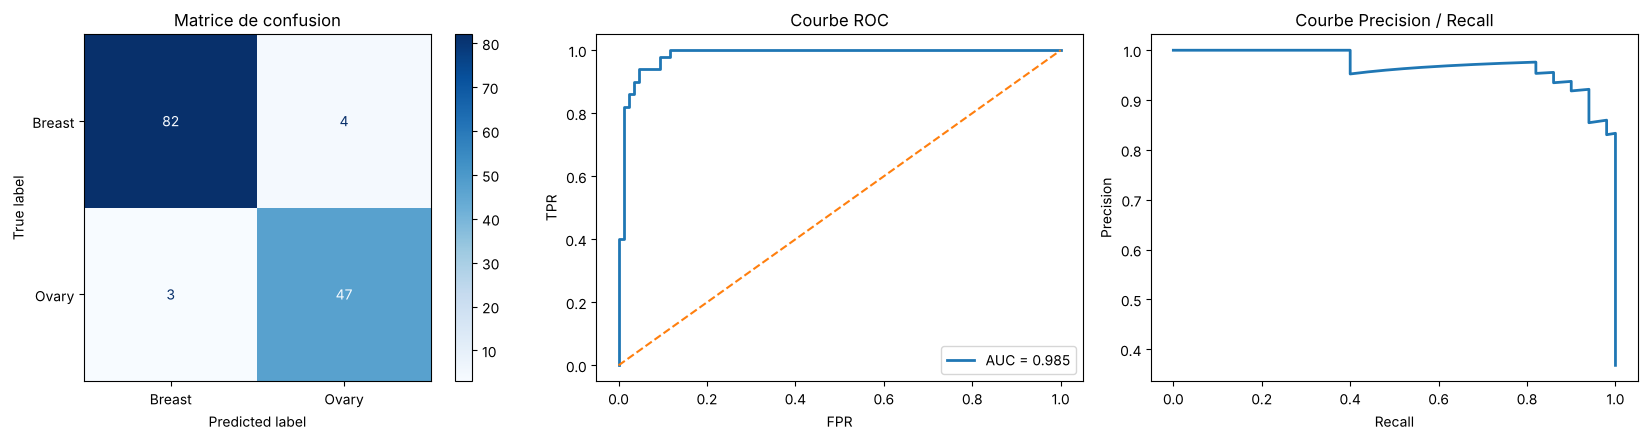

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

ConfusionMatrixDisplay.from_predictions(yg_test, yg_pred, display_labels=['Breast', 'Ovary'], ax=axes[0], cmap='Blues')
axes[0].set_title('Matrice de confusion')

fpr_g, tpr_g, _ = roc_curve(yg_test, yg_proba)
axes[1].plot(fpr_g, tpr_g, linewidth=2, label='AUC = ' + str(round(roc_auc_score(yg_test, yg_proba), 3)))
axes[1].plot([0, 1], [0, 1], '--')
axes[1].set_xlabel('FPR')
axes[1].set_ylabel('TPR')
axes[1].set_title('Courbe ROC')
axes[1].legend(loc=4)

pr, rc, _ = precision_recall_curve(yg_test, yg_proba)
axes[2].plot(rc, pr, linewidth=2)
axes[2].set_xlabel('Recall')
axes[2].set_ylabel('Precision')
axes[2].set_title('Courbe Precision / Recall')
plt.tight_layout()
plt.show()

In [17]:
# validation croisée finale (toutes les données) du modèle choisi
cv_final = cross_validate(best, Xg, yg, cv=skf, scoring=scoring)
for s in scoring:
    print(s.ljust(10), "moyenne =", round(cv_final['test_' + s].mean(), 4), " écart-type =", round(cv_final['test_' + s].std(), 4))

# gènes les plus importants (plus grands coefficients en valeur absolue)
coefs = pd.Series(best[-1].coef_[0], index=Xg.columns)
print()
print("Nombre de coefficients non nuls :", int((coefs != 0).sum()), "sur", len(coefs))
print(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10).round(4))

accuracy   moyenne = 0.9613  écart-type = 0.0067
precision  moyenne = 0.9497  écart-type = 0.0146
recall     moyenne = 0.9446  écart-type = 0.0243
f1         moyenne = 0.9468  écart-type = 0.0096
roc_auc    moyenne = 0.992  écart-type = 0.0036

Nombre de coefficients non nuls : 3000 sur 3000
203854_at       0.0230
1559477_s_at    0.0212
231964_at       0.0210
231736_x_at    -0.0207
207717_s_at     0.0193
203661_s_at     0.0191
1558748_at      0.0190
204447_at       0.0189
222719_s_at     0.0189
224894_at       0.0183
dtype: float64


**Conclusion de la partie 2 (classification Breast / Ovary) :**

- Les données contiennent 542 tumeurs (344 Breast, 198 Ovary) décrites par 3000 gènes, donc beaucoup plus de variables que d'observations utiles : le risque de surapprentissage est important, d'où la nécessité de régulariser. J'ai retiré `ID_REF` qui n'est qu'un identifiant, et j'ai standardisé les gènes.
- La régression logistique avec régularisation L2 fait mieux avec une régularisation forte : en validation croisée l'AUC passe à 0.9907 pour C = 0.001 (meilleur modèle trouvé par GridSearchCV), contre 0.9886 pour C = 1. Un C trop petit (0.0001) ou une pénalité L1 trop forte (C = 0.01) donne un recall trop bas (0.72 et 0.69), le modèle devenant trop contraint.
- Sur le jeu de test (136 tumeurs) : accuracy = 0.949, precision = 0.922, recall = 0.94, spécificité = 0.953, F1 = 0.931, MCC = 0.89, AUC = 0.985, log-loss = 0.20. La matrice de confusion montre 7 erreurs seulement sur 136 (4 faux positifs et 3 faux négatifs).
- En validation croisée sur toutes les données : accuracy = 0.961 (± 0.007), F1 = 0.947 et AUC = 0.992 (± 0.004). Les écarts-types sont faibles, donc le modèle est stable.
- Conclusion : l'expression des gènes permet de bien séparer les tumeurs du sein et de l'ovaire (AUC proche de 0.99). Avec la pénalité L2 tous les 3000 gènes ont un coefficient non nul, chacun de poids très faible (le plus grand est d'environ 0.02), donc la décision repose sur l'ensemble des gènes plutôt que sur quelques-uns.